# 10 - Histórico mensal de água JRC e identificação de eventos de cheia

| | |
|---|---|
| **Tarefa do plano** | S1-09 - identificar eventos de cheia 2006-2026 (JRC mensal + mapas públicos EMS/UNOSAT) |
| **Variáveis (Parte I)** | #42 histórico mensal de água JRC (rótulos), #45 mapas públicos de eventos de cheia |
| **Fonte** | JRC Global Surface Water v1.4 Monthly History via Earth Engine; Copernicus EMS e UNOSAT (manual) |
| **Saída** | `data/raw/labels/jrc_monthly_history/<ano>/` |

Banda `water`: **0 = sem observação, 1 = não é água, 2 = água**. O produto termina
em dezembro de 2021. O valor 0 é informação (nuvem, sem passagem do Landsat), não
é terra seca - nunca deve ser lido como "não é água".

Precisa do `02_static_layers` (ocorrência JRC) para a análise de eventos no fim.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

aoi = G.load_aoi(cfg)                       # AOI das imagens (EPSG:4326)
region = gee.ee_geometry(aoi)
grid30 = G.load_grid(cfg)                   # grelha do projeto a 30 m (EPSG:32736)
grid10 = G.load_grid(cfg, 10)               # grelha a 10 m, encaixada na de 30 m
climate_bounds = tuple(G.load_aoi(cfg, "aoi_climate").total_bounds)   # O, S, E, N
MASK = gee.ee_geometry(G.imagery_mask(cfg))  # distrito + margem: fora daqui as imagens mensais ficam sem dados

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## Parâmetros

**Formato dos ficheiros.** Os valores são guardados como inteiros (`DTYPE`), multiplicados
por `SCALE`, para ocupar menos disco e menos internet sem perda relevante de precisão.
O fator fica gravado dentro do GeoTIFF: ler sempre com `series.read_scaled(ficheiro)`,
que devolve os valores físicos. As bandas `n_obs` e `label_mode` não são multiplicadas.
Com `MASK`, os píxeis fora do distrito + margem ficam sem dados (-9999).

In [2]:
ds = cfg["datasets"]["jrc_monthly"]
DATASET, SOURCE_ID = "jrcmonthly", ds["id"]
BANDS = ["water"]
GRID, DTYPE, START = grid30, "uint8", ds["start"]
SCALE, MASK = 1, None                       # classes 0/1/2, retângulo completo (ficheiros pequenos)
OUT_DIR = config.path(cfg, "jrc_monthly")
builder = datasets.jrc_monthly_builder(cfg)

## Teste com um mês

Correr sempre um mês primeiro e observá-lo antes de lançar o período completo.
`2013-01` está na época chuvosa, quando as nuvens e as cheias são mais prováveis.

In [3]:
TEST_MONTH = "2013-01"
test = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR,
                            start=f"{TEST_MONTH}-01", end=f"{TEST_MONTH}-28", dtype=DTYPE, scale=SCALE, mask=MASK)
test

jrcmonthly:   0%|          | 0/1 [00:00<?, ?it/s]

,period,status,file,n_images
0,2013-01,downloaded,jrcmonthly_marracuene_2013-01_30m.tif,1


<Axes: title={'center': 'jrcmonthly_marracuene_2013-01_30m.tif\nwater'}>

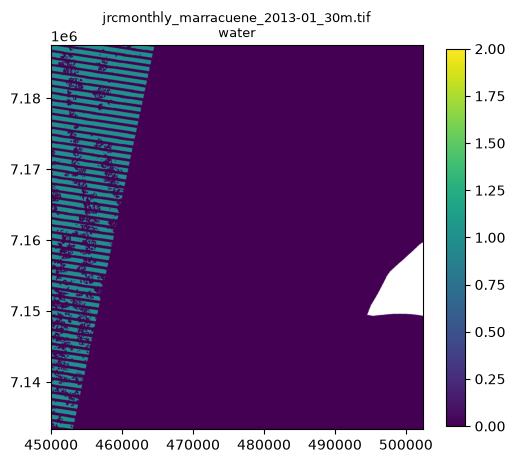

In [4]:
test_file = next(OUT_DIR.rglob(f"*_{TEST_MONTH}_*.tif"))
series.show_raster(test_file, cmap="viridis", vmin=0, vmax=2)

## Período completo

Demora bastante (horas para os datasets de 10 m). Pode ser interrompido e
retomado a qualquer momento; os meses já concluídos são saltados.

In [5]:
log = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR, start=START, end=ds["end"], dtype=DTYPE, scale=SCALE, mask=MASK)
log["status"].value_counts()

jrcmonthly:   0%|          | 0/192 [00:00<?, ?it/s]

status
downloaded    191
exists          1
Name: count, dtype: int64

## Inventário

In [6]:
inv = series.monthly_inventory(OUT_DIR)
expected = [m.strftime("%Y-%m") for m in gee.month_starts(START, ds["end"])]
missing = sorted(set(expected) - set(inv["period"]))
print(f"{len(inv)} ficheiros, {inv['size_mb'].sum() / 1e3:.2f} GB em disco")
print(f"{len(missing)} de {len(expected)} meses sem ficheiro (ausentes na fonte ou com falha):")
print(missing)

192 ficheiros, 0.01 GB em disco
0 de 192 meses sem ficheiro (ausentes na fonte ou com falha):
[]


## Meses candidatos a cheia (a partir dos dados)

Para cada mês: a área observada, a área de água e a área de água **fora da água
permanente** (ocorrência JRC abaixo de 75 %). Os meses em que menos de metade da
AOI foi observada ficam assinalados, porque um mês de cheia com nuvens pode
mostrar pouca água.

,observed_fraction,water_km2,flood_water_km2,well_observed
month,,,,
2021-03,0.983131,1215.8091,56.9502,True
2021-02,0.682063,1055.9934,54.7812,True
2014-03,0.982833,1208.2185,50.7411,True
2014-04,0.981510,1193.7870,36.2907,True
2012-01,0.883452,1152.2133,35.1819,True
2013-02,0.690774,936.2781,20.1852,True
2012-02,0.655248,939.7503,16.0263,True
2006-04,0.976480,1162.6218,12.6216,True
2016-03,0.979799,1167.9705,9.6165,True


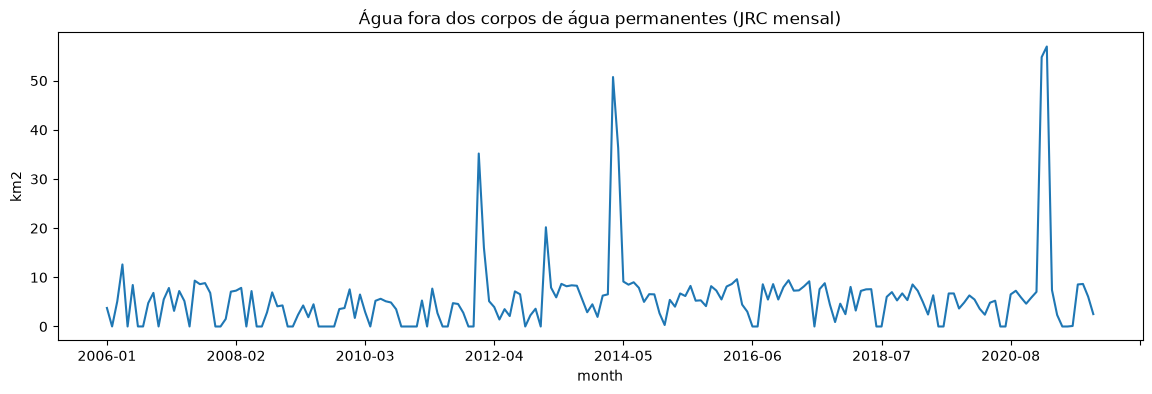

In [7]:
import numpy as np
import rasterio

name = cfg["project"]["aoi_name"]
with rasterio.open(config.path(cfg, "static_surface_water") / f"jrc_gsw_{name}_30m.tif") as src:
    occurrence = src.read(src.descriptions.index("occurrence") + 1)
permanent = (occurrence >= 75) & (occurrence <= 100)
px_km2 = (grid30.res ** 2) / 1e6

rows = []
for f in sorted(OUT_DIR.rglob("*.tif")):
    with rasterio.open(f) as src:
        water = src.read(1)
    observed, is_water = np.isin(water, [1, 2]), water == 2
    rows.append({"month": f.stem.split("_")[2],
                 "observed_fraction": observed.mean(),
                 "water_km2": is_water.sum() * px_km2,
                 "flood_water_km2": (is_water & ~permanent).sum() * px_km2})
water_area = pd.DataFrame(rows).set_index("month")
water_area["well_observed"] = water_area["observed_fraction"] >= 0.5
csv = config.path(cfg, "flood_events", "jrc_monthly_water_area.csv")
water_area.to_csv(csv)

ax = water_area["flood_water_km2"].plot(figsize=(14, 4), ylabel="km2", title="Água fora dos corpos de água permanentes (JRC mensal)")
water_area[water_area["well_observed"]].nlargest(15, "flood_water_km2")

## Catálogo de eventos (a preencher à mão)

A tabela acima apenas sugere meses **candidatos**. Cada evento tem de ser
confirmado numa fonte pública antes de ser usado como rótulo, e nada entra aqui
sem uma referência:

- Copernicus EMS Rapid Mapping, filtro de país *Mozambique*: <https://rapidmapping.emergency.copernicus.eu/>
- UNOSAT: <https://unosat.org/>
- cruzar com as séries do CHIRPS (notebook 03) e do GloFAS (notebook 09)

Os mapas de eventos descarregados ficam em `data/raw/labels/ems_unosat/<event_id>/`.
Depois de 2021 não há dados JRC mensais, por isso os eventos vêm apenas dessas
fontes e dos picos de chuva e de caudal.

In [8]:
catalogue = config.path(cfg, "flood_events", "flood_events_catalogue.csv")
if not catalogue.exists():
    pd.DataFrame(columns=["event_id", "start_date", "end_date", "description", "source", "activation_code",
                          "source_url", "covers_aoi", "map_folder", "confirmed_by", "notes"]).to_csv(catalogue, index=False)
    print("modelo vazio criado:", catalogue.relative_to(ROOT))
pd.read_csv(catalogue)

modelo vazio criado: data/raw/labels/flood_events/flood_events_catalogue.csv


,event_id,start_date,end_date,description,source,activation_code,source_url,covers_aoi,map_folder,confirmed_by,notes
